# Examen Final

## Caso 1

In [9]:
# Funciones auxiliares — Problema 1: Regresión (Housing)
# Son las mismas que usamos en los laboratorios de regresión lineal y árboles (caso MPG).
# Ejecuta esta celda una vez; después sólo llama a las funciones.
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)


def plot_frequencies(df, columns, top_n=None):
    """Gráfica de barras con la frecuencia de cada categoría (top_n limita a las más comunes)."""
    for col in columns:
        freq = df[col].value_counts()
        if top_n:
            freq = freq.head(top_n)
        freq_df = freq.rename_axis(col).reset_index(name='Frecuencia')

        title = f'Frecuencias de {col}'
        if top_n and df[col].nunique() > top_n:
            title += f' (top {top_n})'

        fig = px.bar(freq_df, x=col, y='Frecuencia', title=title)
        fig.update_layout(xaxis={'categoryorder': 'total descending'})
        fig.show()


def evaluar_regresion(nombre, y_true, y_pred):
    """Imprime y regresa R², RMSE, MAE y MAPE (%) de un modelo de regresión."""
    metricas = {
        'modelo': nombre,
        'R²': round(r2_score(y_true, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        'MAE': round(mean_absolute_error(y_true, y_pred), 3),
        'MAPE (%)': round(mean_absolute_percentage_error(y_true, y_pred) * 100, 2),
    }
    print(f"{nombre}: R² {metricas['R²']} | RMSE {metricas['RMSE']} | "
          f"MAE {metricas['MAE']} | MAPE {metricas['MAPE (%)']}%")
    return metricas


def plot_importancias(modelo, columnas, top_n=None):
    """Importancia de cada variable en un modelo basado en árboles."""
    imp = pd.Series(modelo.feature_importances_, index=columnas).sort_values(ascending=True)
    if top_n:
        imp = imp.tail(top_n)

    fig = px.bar(
        x=imp.values, y=imp.index, orientation='h', text_auto='.3f',
        labels={'x': 'Importancia (reducción de impureza)', 'y': ''},
        title='Importancia de variables', template='plotly_white'
    )
    fig.update_layout(width=800, height=450)
    fig.show()
    return imp.sort_values(ascending=False)

In [10]:
import pandas as pd

url = 'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/Housing.csv'
df = pd.read_csv(url)

numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categoricas = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Variables numéricas:", len(numericas))
print(numericas)
print("\nVariables categóricas:", len(categoricas))
print(categoricas)
print("\nForma del dataset:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

Variables numéricas: 6
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Variables categóricas: 7
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

Forma del dataset: (545, 13)

Tipos de datos:
price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object


/tmp/ipykernel_40705/710630072.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [11]:
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Shape de X_Train:", X_train.shape)
print("Shape de X_Test:", X_test.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de y_test:", y_test.shape)

Shape de X_Train: (436, 12)
Shape de X_Test: (109, 12)
Shape de y_train: (436,)
Shape de y_test: (109,)


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

X_train_enc = pd.get_dummies(X_train, drop_first=True)
X_test_enc = pd.get_dummies(X_test, drop_first=True)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

lr = LinearRegression()
lr.fit(X_train_enc, y_train)
y_pred_lr = lr.predict(X_test_enc)

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_enc, y_train)
y_pred_dt = dt.predict(X_test_enc)

metricas_lr = evaluar_regresion('Regresión Lineal', y_test, y_pred_lr)
metricas_dt = evaluar_regresion('Árbol de Decisión', y_test, y_pred_dt)

Regresión Lineal: R² 0.6529 | RMSE 1324506.9601 | MAE 970043.404 | MAPE 21.04%
Árbol de Decisión: R² 0.4771 | RMSE 1625669.9043 | MAE 1195266.055 | MAPE 24.93%


## Caso 2

In [13]:
# Funciones auxiliares — Problema 2: Clasificación (UCI Credit Card)
# Son las mismas que usamos en los laboratorios de regresión logística y árboles (caso Titanic).
# Ejecuta esta celda una vez; después sólo llama a las funciones.
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.preprocessing import StandardScaler


def plot_frequencies(df, columns, top_n=None):
    """Gráfica de barras con la frecuencia de cada categoría (top_n limita a las más comunes)."""
    for col in columns:
        freq = df[col].value_counts()
        if top_n:
            freq = freq.head(top_n)
        freq_df = freq.rename_axis(col).reset_index(name='Frecuencia')

        title = f'Frecuencias de {col}'
        if top_n and df[col].nunique() > top_n:
            title += f' (top {top_n})'

        fig = px.bar(freq_df, x=col, y='Frecuencia', title=title)
        fig.update_layout(xaxis={'categoryorder': 'total descending'})
        fig.show()


def escalar(X_train, X_test):
    """Estandariza (media 0, desviación 1) ajustando sólo con train. Regresa ambos DataFrames."""
    escalador = StandardScaler().fit(X_train)
    X_train_s = pd.DataFrame(escalador.transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test_s = pd.DataFrame(escalador.transform(X_test), columns=X_test.columns, index=X_test.index)
    return X_train_s, X_test_s


def evaluar_clasificador(nombre, y_true, y_pred):
    """Imprime y regresa exactitud (accuracy), precisión, recall y F1.

    Con dos clases, precisión, recall y F1 se calculan para la clase positiva (1).
    Con más de dos clases son el promedio simple de las clases (average='macro').
    """
    binario = len(np.unique(np.concatenate([np.asarray(y_true), np.asarray(y_pred)]))) <= 2
    promedio = 'binary' if binario else 'macro'
    metricas = {
        'modelo': nombre,
        'exactitud': round(accuracy_score(y_true, y_pred), 4),
        'precisión': round(precision_score(y_true, y_pred, average=promedio, zero_division=0), 4),
        'recall': round(recall_score(y_true, y_pred, average=promedio, zero_division=0), 4),
        'F1': round(f1_score(y_true, y_pred, average=promedio, zero_division=0), 4),
    }
    print(f"{nombre}: exactitud {metricas['exactitud']} | precisión {metricas['precisión']} "
          f"| recall {metricas['recall']} | F1 {metricas['F1']}")
    return metricas


def plot_matriz_confusion(y_true, y_pred, clases=None, etiquetas=None, title='Matriz de confusión'):
    """Aciertos y errores del clasificador: la diagonal son los aciertos.

    clases: los valores de la variable objetivo en el orden en que quieres verlos, p. ej. [0, 1].
            Si no las pasas, se ordenan de menor a mayor.
    etiquetas: nombres a mostrar para esas clases (opcional), p. ej. ['Pagó', 'Incumplió'].
    """
    if clases is None:
        clases = sorted(set(np.asarray(y_true)) | set(np.asarray(y_pred)))
    clases = list(clases)
    etiquetas = list(etiquetas) if etiquetas is not None else clases

    cm = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=clases),
        index=[f'Real: {e}' for e in etiquetas],
        columns=[f'Predicho: {e}' for e in etiquetas]
    )

    fig = px.imshow(cm, text_auto=True, color_continuous_scale='Blues', title=title)
    fig.update_layout(width=650, height=450)
    fig.show()
    return cm

In [14]:
url = 'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/UCI_Credit_Card.csv'
df_cc = pd.read_csv(url, index_col='ID')

df_cc = df_cc.rename(columns={'default.payment.next.month': 'IsDefaulter'})

print(df_cc['IsDefaulter'].value_counts())

IsDefaulter
0    23364
1     6636
Name: count, dtype: int64


In [15]:
df_cc['EDUCATION'] = df_cc['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

print(df_cc['EDUCATION'].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64


In [16]:
df_cc['MARRIAGE'] = df_cc['MARRIAGE'].replace({0: 3})

print(df_cc['MARRIAGE'].value_counts().sort_index())

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [17]:
print(round(df_cc[df_cc['IsDefaulter'] == 1]['AGE'].mean(), 2))

35.73


In [18]:
df_dummies = pd.get_dummies(df_cc, columns=['EDUCATION', 'MARRIAGE'])

print(df_dummies.shape)
print(df_dummies.columns.tolist())

(30000, 29)
['LIMIT_BAL', 'SEX', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'IsDefaulter', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']


In [19]:
df_dummies_pay = pd.get_dummies(
    df_dummies,
    columns=['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6'],
    drop_first=True
)

print(df_dummies_pay.shape)

(30000, 81)


In [20]:
for col in ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']:
    print(col, df_dummies[col].nunique(), sorted(df_dummies[col].unique()))

PAY_0 11 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 11 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 11 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 11 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5 10 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6 10 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [21]:
if 'ID' in df_dummies_pay.columns:
    df_dummies_pay = df_dummies_pay.drop(columns=['ID'])
    
print(df_dummies_pay.shape[1])

81


In [22]:
from sklearn.model_selection import train_test_split

X = df_dummies_pay.drop(columns=['IsDefaulter'])
y = df_dummies_pay['IsDefaulter']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.33, 
    random_state=42, 
    stratify=df_dummies_pay['IsDefaulter']
)

print(len(X_train))

20100


In [23]:
from sklearn.linear_model import LogisticRegression

X_train_s, X_test_s = escalar(X_train, X_test)

lr = LogisticRegression(
    C=10, 
    penalty='l2',  
    random_state=42, 
    class_weight='balanced', 
    max_iter=2000
)

lr.fit(X_train_s, y_train)

y_pred_lr = lr.predict(X_test_s)

metricas_lr = evaluar_clasificador('Regresión Logística', y_test, y_pred_lr)

/workspaces/aprendizaje-no-supervisado-610439/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Regresión Logística: exactitud 0.7754 | precisión 0.4932 | recall 0.5658 | F1 0.527


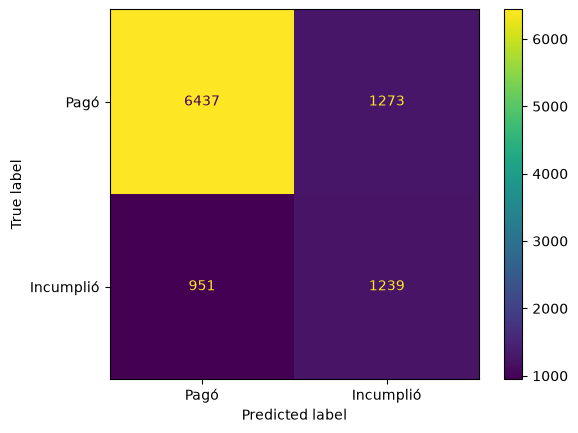

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, 
    display_labels=['Pagó', 'Incumplió']
)
plt.show()

In [25]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=20, 
    min_samples_split=0.1, 
    random_state=42, 
    class_weight='balanced'
)

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

metricas_dt = evaluar_clasificador('Árbol de Decisión', y_test, y_pred_dt)

Árbol de Decisión: exactitud 0.7144 | precisión 0.4103 | recall 0.6648 | F1 0.5074


## Caso 3

In [26]:
# Funciones auxiliares — Problema 3: Clustering (College Data)
# Son las mismas que usamos en los laboratorios de K-Means, DBSCAN y PCA.
# Ejecuta esta celda una vez; después sólo llama a las funciones.
#   Nuevo: evaluar_clustering ahora reporta DOS silhouettes:
#        'silhouette'           → como la calcula sklearn: el ruido (-1) cuenta como un grupo más.
#        'silhouette_sin_ruido' → como en clase: sólo los puntos que quedaron en un cluster.
#   Nuevo: tabla_metricas_k usa n_init='auto' (el valor por defecto de KMeans) en vez de n_init=10.
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score


def evaluar_clustering(nombre, X, labels):
    """Número de clusters (sin contar el ruido), % de ruido y silhouette de un agrupamiento."""
    X = np.asarray(X)
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))
    fila = {
        'modelo': nombre,
        'n_clusters': n_clusters,
        'pct_ruido': float(round(100 * (~mask).mean(), 1)),
    }
    # sklearn: todas las etiquetas, el ruido incluido como un grupo (necesita al menos 2 etiquetas)
    fila['silhouette'] = (float(round(silhouette_score(X, labels), 3))
                          if len(np.unique(labels)) >= 2 else np.nan)
    # Sin ruido: sólo los puntos asignados a un cluster (necesita al menos 2 clusters)
    fila['silhouette_sin_ruido'] = (float(round(silhouette_score(X[mask], labels[mask]), 3))
                                    if n_clusters >= 2 else np.nan)
    return fila


def tabla_metricas_k(X, ks, random_state=42):
    """Ajusta K-Means para cada k y regresa una tabla con la inercia (para el codo) y la silhouette."""
    filas = []
    for k in ks:
        modelo = KMeans(n_clusters=k, n_init='auto', random_state=random_state).fit(X)
        fila = evaluar_clustering(f'k={k}', X, modelo.labels_)
        filas.append({'k': k, 'inercia': float(round(modelo.inertia_, 1)), 'silhouette': fila['silhouette']})
    return pd.DataFrame(filas)


def grilla_dbscan(X, eps_values, min_samples_values):
    """Ajusta DBSCAN para cada combinación de eps y min_samples.
    Regresa una tabla con el número de clusters, % de ruido y ambas silhouettes."""
    filas = []
    for eps in eps_values:
        for ms in min_samples_values:
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            fila = evaluar_clustering(f'eps={eps}, ms={ms}', X, labels)
            filas.append({'eps': eps, 'min_samples': ms, **fila})
    return pd.DataFrame(filas).drop(columns='modelo')


def perfil_clusters(df, labels, columnas):
    """Promedio de cada variable por cluster, con tamaño y porcentaje. Sirve para ponerle nombre a cada grupo."""
    datos = df[columnas].copy()
    datos['cluster'] = np.asarray(labels)
    perfil = datos.groupby('cluster')[columnas].mean().round(1)
    perfil.insert(0, 'n', datos['cluster'].value_counts().sort_index())
    perfil.insert(1, 'pct', (100 * perfil['n'] / perfil['n'].sum()).round(1))
    perfil.index = ['Ruido' if c == -1 else f'Cluster {c}' for c in perfil.index]
    return perfil


def plot_codo(ks, inercias):
    """Método del codo: inercia (suma de distancias² al centroide) para cada k."""
    fig = px.line(
        x=list(ks),
        y=list(inercias),
        markers=True,
        labels={'x': 'Número de clusters (k)', 'y': 'Inercia'},
        title='Método del codo'
    )
    fig.update_layout(width=750, height=450)
    fig.show()


def plot_silueta_k(tabla):
    """Silhouette promedio para cada k (tabla de tabla_metricas_k). Más alto es mejor."""
    fig = px.line(
        tabla,
        x='k',
        y='silhouette',
        markers=True,
        labels={'k': 'Número de clusters (k)', 'silhouette': 'Silhouette promedio'},
        title='Silhouette según k (↑ mejor)'
    )
    fig.update_xaxes(dtick=1)
    fig.update_layout(width=750, height=450)
    fig.show()


def plot_k_distancia(X, k, eps=None):
    """Distancia que necesita cada punto para tener k vecinos (contándose a sí mismo), ordenada.
    Usa k = min_samples. El 'codo' sugiere un buen eps; eps (opcional) dibuja una línea de referencia."""
    from sklearn.neighbors import NearestNeighbors

    vecinos = NearestNeighbors(n_neighbors=k).fit(X)
    distancias, _ = vecinos.kneighbors(X)
    d_k = np.sort(distancias[:, -1])

    fig = px.line(
        x=np.arange(len(d_k)),
        y=d_k,
        labels={'x': 'Puntos ordenados por distancia', 'y': f'Distancia para tener {k} vecinos (incluido él)'},
        title=f'Gráfica de k-distancia (k = {k})'
    )
    if eps is not None:
        fig.add_hline(y=eps, line_dash='dash', line_color='red',
                      annotation_text=f'eps = {eps}', annotation_position='top left')
    fig.update_layout(width=750, height=450)
    fig.show()


def plot_varianza_explicada(pca):
    """Scree plot: varianza explicada por componente (barras) y acumulada (línea)."""
    ratio = pca.explained_variance_ratio_
    n = np.arange(1, len(ratio) + 1)
    fig = go.Figure()
    fig.add_trace(go.Bar(x=n, y=ratio, name='Por componente'))
    fig.add_trace(go.Scatter(x=n, y=np.cumsum(ratio), mode='lines+markers', name='Acumulada'))
    for umbral in (0.80, 0.95):
        fig.add_hline(y=umbral, line_dash='dot', line_color='gray',
                      annotation_text=f'{umbral:.0%}', annotation_position='right')
    fig.update_layout(
        title='Varianza explicada por componente',
        xaxis={'title': 'Componente principal', 'dtick': 1 if len(ratio) <= 30 else None},
        yaxis={'title': 'Proporción de varianza', 'tickformat': '.0%', 'range': [0, 1.05]},
        width=800,
        height=450
    )
    fig.show()

In [27]:
url = 'https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/College_Data.csv'
college = pd.read_csv(url)
X = college.drop(columns=['College'])

In [28]:
X_numerico = pd.get_dummies(X, columns=['Private'], drop_first=True, dtype=int)
modelo_kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
etiquetas = modelo_kmeans.fit_predict(X_numerico)
score = silhouette_score(X_numerico, etiquetas)
print(f'Silhouette Score (K=2): {score:.2f}')

Silhouette Score (K=2): 0.54


In [29]:
from sklearn.preprocessing import StandardScaler

X_escalado = StandardScaler().fit_transform(X_numerico)
etiquetas_dbscan = DBSCAN(eps=2.0, min_samples=5).fit_predict(X_escalado)
n_clusters = len(set(etiquetas_dbscan) - {-1})
print(f'Clusters detectados (sin ruido): {n_clusters}')

Clusters detectados (sin ruido): 3


In [30]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.8, random_state=42)
X_pca = pca.fit_transform(X_escalado)

modelo_kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init='auto')
etiquetas_kmeans_pca = modelo_kmeans_pca.fit_predict(X_pca)
score_pca = silhouette_score(X_pca, etiquetas_kmeans_pca)
print(f'Silhouette Score (PCA + K-Means, K=3): {score_pca:.2f}')

Silhouette Score (PCA + K-Means, K=3): 0.29
